# 10 — DINOv2 Slice-Attention Multiple Instance Learning (MIL)

**Purpose.** Train a study-level multi-label classifier over the frozen 384-dimensional DINOv2 embeddings produced by Notebook 09. A gated-attention module assigns a weight to each 2.5D neighbouring-slice instance in a study; the weighted study representation predicts the 12 findings.

```text
Notebook 09: frozen DINOv2 embeddings (one vector per 2.5D instance)
        ↓
Notebook 10: attention over all 2.5D instances in each study
        ↓
12 study-level sigmoid probabilities + attention weights
```

This is the **flat slice-attention baseline**: instances from all MRI series in the same study form one bag. Series boundaries are preserved in the saved metadata for analysis, but series-level attention is not yet applied here; that is introduced in the later series/hierarchical MIL stages.

## Outputs

Fold results, mean ± SD summaries, out-of-fold (OOF) study predictions, per-finding metrics, error analysis, per-instance attention weights, plots, and one checkpoint per fold are saved under `/kaggle/working/`.

> **Evaluation boundary:** this notebook uses only the 58 fully labelled gold studies and the fixed study-level folds created in Notebook 05. It does not use report text or weak labels and does not perform final test-set inference.

## 1. Imports and configuration

In [1]:
import os
import gc
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    hamming_loss,
    accuracy_score,
)

warnings.filterwarnings("ignore")

SEED = 42
N_FOLDS = 5
NUM_CLASSES = 12
CLASSIFICATION_THRESHOLD = 0.50

# Small-data MIL head. The DINOv2 backbone is frozen upstream; only this
# attention module and classifier are trained in this notebook.
EPOCHS = 50
PATIENCE = 10
ATTENTION_DIM = 128
HIDDEN_DIM = 128
DROPOUT = 0.25
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
MAX_GRAD_NORM = 1.0

OUTPUT_DIR = "/kaggle/working"
os.makedirs(OUTPUT_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

LABEL_COLS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture",
]


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Output directory:", OUTPUT_DIR)
print("Labels:", len(LABEL_COLS))

Device: cuda
GPU: Tesla T4
Output directory: /kaggle/working
Labels: 12


## 2. Locate the competition data and Notebook 09 artifacts

In [2]:
SEARCH_ROOTS = ["/kaggle/input", "/kaggle/working"]
# Avoid walking through the many individual DICOM files in image folders.
PRUNE_DIRS = {
    "train_images", "test_images", "train_series", "test_series",
    "processed_data", "__pycache__", ".git", ".ipynb_checkpoints"
}


def find_all_files(filename):
    matches = []
    for base in SEARCH_ROOTS:
        if not os.path.exists(base):
            continue
        for current, dirs, files in os.walk(base):
            dirs[:] = [d for d in dirs if d not in PRUNE_DIRS]
            if filename in files:
                matches.append(os.path.join(current, filename))
    return sorted(set(matches))


def choose_file(filename, preferred_tokens=(), required=True):
    candidates = find_all_files(filename)
    if not candidates:
        if required:
            raise FileNotFoundError(
                f"Could not find {filename}. Add the RSNA competition dataset and/or "
                "the saved output of Notebook 09 under Kaggle 'Add Input'."
            )
        return None
    for token in preferred_tokens:
        chosen = [p for p in candidates if token.lower() in p.lower()]
        if chosen:
            return chosen[0]
    return candidates[0]


TRAIN_CSV_PATH = choose_file(
    "train.csv",
    preferred_tokens=("rsna-knee-abnormality-detection", "competitions/rsna", "rsna-knee"),
)
EMBEDDING_PATH = choose_file(
    "dinov2_vits14_embeddings_float16.npy",
    preferred_tokens=("09", "dinov2"),
)
METADATA_PATH = choose_file(
    "dinov2_vits14_embedding_metadata.csv",
    preferred_tokens=("09", "dinov2"),
)
MANIFEST_PATH = choose_file(
    "dinov2_vits14_embedding_manifest.json",
    preferred_tokens=("09", "dinov2"),
    required=False,
)
COVERAGE_PATH = choose_file(
    "dinov2_vits14_coverage_summary.csv",
    preferred_tokens=("09", "dinov2"),
    required=False,
)

print("Competition train.csv:", TRAIN_CSV_PATH)
print("DINOv2 embeddings:", EMBEDDING_PATH)
print("Embedding metadata:", METADATA_PATH)
print("Manifest:", MANIFEST_PATH or "not attached (optional)")
print("Coverage summary:", COVERAGE_PATH or "not attached (optional)")

Competition train.csv: /kaggle/input/competitions/rsna-knee-abnormality-detection/train.csv
DINOv2 embeddings: /kaggle/input/notebooks/minnieg12/09-dinov2/dinov2_vits14_embeddings_float16.npy
Embedding metadata: /kaggle/input/notebooks/minnieg12/09-dinov2/dinov2_vits14_embedding_metadata.csv
Manifest: /kaggle/input/notebooks/minnieg12/09-dinov2/dinov2_vits14_embedding_manifest.json
Coverage summary: /kaggle/input/notebooks/minnieg12/09-dinov2/dinov2_vits14_coverage_summary.csv


## 3. Load artifacts and run integrity checks

In [3]:
if MANIFEST_PATH:
    with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
        embedding_manifest = json.load(f)
    print("Notebook 09 manifest:", embedding_manifest)
    if embedding_manifest.get("smoke_test") is True:
        raise RuntimeError(
            "The attached Notebook 09 output is marked as a smoke test. "
            "Rerun Notebook 09 with SMOKE_TEST=False and DATA_SCOPE='gold', save a new version, "
            "and attach that output before running Notebook 10."
        )
    if embedding_manifest.get("data_scope", "gold") != "gold":
        raise RuntimeError(
            "Notebook 10 is configured for the 58-study gold-label experiment. "
            "Attach the Notebook 09 output generated with DATA_SCOPE='gold'."
        )
else:
    embedding_manifest = {}

train = pd.read_csv(TRAIN_CSV_PATH)
metadata = pd.read_csv(METADATA_PATH)
embeddings_memmap = np.load(EMBEDDING_PATH, mmap_mode="r")

print("Competition train rows:", len(train))
print("Embedding array shape:", embeddings_memmap.shape)
print("Metadata shape:", metadata.shape)

required_metadata_cols = [
    "Embedding_Index", "StudyInstanceUID", "SeriesInstanceUID", "fold",
    "Prev_Slice_Index", "Center_Slice_Index", "Next_Slice_Index",
]
missing_metadata_cols = [c for c in required_metadata_cols if c not in metadata.columns]
if missing_metadata_cols:
    raise ValueError(
        "Notebook 09 metadata is missing required columns: " + str(missing_metadata_cols)
    )
missing_label_cols = [c for c in ["StudyInstanceUID"] + LABEL_COLS if c not in train.columns]
if missing_label_cols:
    raise ValueError("Competition train.csv is missing columns: " + str(missing_label_cols))

if embeddings_memmap.ndim != 2:
    raise ValueError(f"Expected a 2D embedding array [instances, features], got {embeddings_memmap.shape}")
if len(metadata) != embeddings_memmap.shape[0]:
    raise ValueError(
        f"Embedding/metadata row mismatch: {embeddings_memmap.shape[0]} vectors vs {len(metadata)} metadata rows."
    )

metadata["Embedding_Index"] = pd.to_numeric(metadata["Embedding_Index"], errors="raise").astype(int)
metadata["fold"] = pd.to_numeric(metadata["fold"], errors="raise").astype(int)
metadata["StudyInstanceUID"] = metadata["StudyInstanceUID"].astype(str)
metadata["SeriesInstanceUID"] = metadata["SeriesInstanceUID"].astype(str)
metadata = metadata.sort_values("Embedding_Index").reset_index(drop=True)
expected_indices = np.arange(len(metadata), dtype=int)
if not np.array_equal(metadata["Embedding_Index"].to_numpy(), expected_indices):
    raise ValueError(
        "Embedding_Index must be unique and contiguous from 0 to N-1 so each metadata row "
        "maps to the matching row in the saved embedding array. Rerun Notebook 09 if needed."
    )
if metadata["Embedding_Index"].duplicated().any():
    raise ValueError("Duplicate Embedding_Index values found in Notebook 09 metadata.")

embeddings = np.asarray(embeddings_memmap, dtype=np.float32)
del embeddings_memmap
if not np.isfinite(embeddings).all():
    raise ValueError("Non-finite values found in DINOv2 embeddings.")
if embeddings.shape[1] != 384:
    raise ValueError(f"Expected 384-dimensional DINOv2 ViT-S/14 vectors, found {embeddings.shape[1]} dimensions.")

print("Embeddings loaded as float32:", embeddings.shape)
print("Embedding metadata indices align with the array: PASSED")
print("Finite embedding values: PASSED")

Notebook 09 manifest: {'model_name': 'hf_hub:timm/vit_small_patch14_dinov2.lvd142m', 'embedding_dim': 384, 'input_size': [3, 518, 518], 'source_size': [3, 224, 224], 'data_scope': 'gold', 'smoke_test': False, 'num_studies': 58, 'num_embeddings': 10528, 'dtype': 'float16', 'seed': 42}
Competition train rows: 4407
Embedding array shape: (10528, 384)
Metadata shape: (10528, 12)
Embeddings loaded as float32: (10528, 384)
Embedding metadata indices align with the array: PASSED
Finite embedding values: PASSED


## 4. Join the 12 gold labels and validate study-level folds

In [4]:
# Cast labels to numeric, then select only studies with all 12 structured labels.
train["StudyInstanceUID"] = train["StudyInstanceUID"].astype(str)
for col in LABEL_COLS:
    train[col] = pd.to_numeric(train[col], errors="coerce")

gold_df = train.dropna(subset=LABEL_COLS).copy()
if gold_df["StudyInstanceUID"].duplicated().any():
    raise ValueError("Duplicate StudyInstanceUID rows in competition train.csv.")

# Labels and fold assignments are study-level. Each study must have exactly one fold.
fold_nunique = metadata.groupby("StudyInstanceUID")["fold"].nunique()
if not (fold_nunique == 1).all():
    bad = fold_nunique[fold_nunique != 1].index.tolist()[:10]
    raise ValueError(f"Fold assignment is not unique per study. Example IDs: {bad}")

fold_map = (
    metadata[["StudyInstanceUID", "fold"]]
    .drop_duplicates()
    .copy()
)
gold_df = gold_df.merge(fold_map, on="StudyInstanceUID", how="inner", validate="one_to_one")

meta_studies = set(metadata["StudyInstanceUID"].unique())
gold_studies = set(gold_df["StudyInstanceUID"].unique())
missing_from_embeddings = sorted(gold_studies - meta_studies)
extra_in_embeddings = sorted(meta_studies - gold_studies)

print("Complete gold-labelled studies in train.csv:", len(train.dropna(subset=LABEL_COLS)))
print("Gold studies represented in embeddings:", len(gold_studies))
print("Fold counts (studies):")
print(gold_df["fold"].value_counts().sort_index())
print("2.5D embedding instances:", len(metadata))
print("Series represented:", metadata["SeriesInstanceUID"].nunique())

if missing_from_embeddings or extra_in_embeddings:
    raise ValueError(
        "Gold-label/embedding study coverage mismatch. "
        f"Missing embedding studies (first 5): {missing_from_embeddings[:5]}; "
        f"non-gold studies in embeddings (first 5): {extra_in_embeddings[:5]}. "
        "Attach the complete 58-study gold output from Notebook 09."
    )
if len(gold_df) != 58:
    raise ValueError(
        f"Expected 58 fully labelled studies for this experiment, found {len(gold_df)}. "
        "Check the competition dataset and Notebook 09 output."
    )
if set(gold_df["fold"].unique()) != set(range(N_FOLDS)):
    raise ValueError(f"Expected fold IDs 0..{N_FOLDS-1}, found {sorted(gold_df['fold'].unique())}")
if not gold_df[LABEL_COLS].isin([0, 1]).all().all():
    raise ValueError("Gold labels must be binary 0/1 values.")

# Stable lookup structures used by the cross-validation loop.
gold_df = gold_df.sort_values(["fold", "StudyInstanceUID"]).reset_index(drop=True)
LABEL_BY_STUDY = {
    row["StudyInstanceUID"]: row[LABEL_COLS].to_numpy(dtype=np.float32)
    for _, row in gold_df.iterrows()
}
FOLD_BY_STUDY = dict(zip(gold_df["StudyInstanceUID"], gold_df["fold"].astype(int)))
STUDY_IDS = sorted(gold_df["StudyInstanceUID"].tolist())

print("Study coverage and folds: PASSED")
display(gold_df[["StudyInstanceUID", "fold"] + LABEL_COLS].head())

Complete gold-labelled studies in train.csv: 58
Gold studies represented in embeddings: 58
Fold counts (studies):
fold
0    12
1    12
2    12
3    11
4    11
Name: count, dtype: int64
2.5D embedding instances: 10528
Series represented: 336
Study coverage and folds: PASSED


,StudyInstanceUID,fold,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10095687747295410396...,0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
1,1.2.826.0.1.3680043.8.498.11287937729196958426...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,1.2.826.0.1.3680043.8.498.11548045715264151632...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
3,1.2.826.0.1.3680043.8.498.12606657226568558340...,0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.2.826.0.1.3680043.8.498.12801308844398614687...,0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0


## 5. Create study bags and define gated-attention MIL

In [5]:
# One bag = all DINOv2 2.5D-instance embeddings belonging to one StudyInstanceUID.
# The model learns one attention distribution over the instances in the study.
STUDY_EMBEDDING_INDICES = {}
STUDY_METADATA = {}
for study_id, group in metadata.groupby("StudyInstanceUID", sort=False):
    group = group.sort_values("Embedding_Index").reset_index(drop=True)
    STUDY_EMBEDDING_INDICES[study_id] = torch.as_tensor(
        group["Embedding_Index"].to_numpy(dtype=np.int64),
        dtype=torch.long,
        device=DEVICE,
    )
    STUDY_METADATA[study_id] = group

EMBEDDINGS_TENSOR = torch.as_tensor(embeddings, dtype=torch.float32, device=DEVICE)
INPUT_DIM = int(embeddings.shape[1])


class GatedAttentionMIL(nn.Module):
    """Gated attention pooling over a variable-length bag of instance vectors."""
    def __init__(self, input_dim=384, attention_dim=128, hidden_dim=128,
                 num_classes=12, dropout=0.25):
        super().__init__()
        self.instance_norm = nn.LayerNorm(input_dim)
        self.attention_v = nn.Linear(input_dim, attention_dim)
        self.attention_u = nn.Linear(input_dim, attention_dim)
        self.attention_w = nn.Linear(attention_dim, 1, bias=False)
        self.classifier = nn.Sequential(
            nn.LayerNorm(input_dim),
            nn.Linear(input_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, instance_embeddings, return_attention=False):
        if instance_embeddings.ndim != 2 or instance_embeddings.shape[0] == 0:
            raise ValueError("Expected a non-empty [instances, features] study bag.")
        x = self.instance_norm(instance_embeddings)
        gated = torch.tanh(self.attention_v(x)) * torch.sigmoid(self.attention_u(x))
        attention_logits = self.attention_w(gated).squeeze(-1)
        attention_weights = torch.softmax(attention_logits, dim=0)
        study_embedding = torch.sum(attention_weights.unsqueeze(-1) * x, dim=0)
        logits = self.classifier(study_embedding)
        if return_attention:
            return logits, attention_weights
        return logits


def create_pos_weight(train_study_ids):
    y = np.stack([LABEL_BY_STUDY[sid] for sid in train_study_ids]).astype(np.float32)
    positives = y.sum(axis=0)
    negatives = len(y) - positives
    weights = np.ones(NUM_CLASSES, dtype=np.float32)
    valid = positives > 0
    weights[valid] = negatives[valid] / positives[valid]
    weights = np.clip(weights, 1.0, 20.0)
    return torch.tensor(weights, dtype=torch.float32, device=DEVICE)

print("Input dimension:", INPUT_DIM)
print("Study bags:", len(STUDY_EMBEDDING_INDICES))
print("Instances per study (descriptive statistics):")
display(metadata.groupby("StudyInstanceUID").size().describe().to_frame("instances"))

Input dimension: 384
Study bags: 58
Instances per study (descriptive statistics):


,instances
count,58.000000
mean,181.517241
std,82.382983
min,75.000000
25%,124.000000
50%,169.000000
75%,198.750000
max,572.000000


## 6. Evaluation utilities

In [6]:
def compute_per_class_metrics(y_true, y_prob, threshold=CLASSIFICATION_THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    y_pred = (y_prob >= threshold).astype(int)
    rows = []

    for j, label in enumerate(LABEL_COLS):
        true_j = y_true[:, j]
        prob_j = y_prob[:, j]
        pred_j = y_pred[:, j]
        tp = int(np.sum((true_j == 1) & (pred_j == 1)))
        tn = int(np.sum((true_j == 0) & (pred_j == 0)))
        fp = int(np.sum((true_j == 0) & (pred_j == 1)))
        fn = int(np.sum((true_j == 1) & (pred_j == 0)))
        precision = tp / (tp + fp) if (tp + fp) else np.nan
        recall = tp / (tp + fn) if (tp + fn) else np.nan
        specificity = tn / (tn + fp) if (tn + fp) else np.nan
        f1 = (
            2 * precision * recall / (precision + recall)
            if np.isfinite(precision) and np.isfinite(recall) and (precision + recall) > 0
            else 0.0
        )
        auc = roc_auc_score(true_j, prob_j) if len(np.unique(true_j)) == 2 else np.nan
        pr_auc = average_precision_score(true_j, prob_j) if len(np.unique(true_j)) == 2 else np.nan
        rows.append({
            "label": label,
            "prevalence": float(true_j.mean()),
            "positive_count": int(true_j.sum()),
            "precision": precision,
            "recall": recall,
            "sensitivity": recall,
            "specificity": specificity,
            "f1": f1,
            "roc_auc": auc,
            "pr_auc": pr_auc,
            "tp": tp, "tn": tn, "fp": fp, "fn": fn,
        })
    return pd.DataFrame(rows)


def compute_metrics(y_true, y_prob, threshold=CLASSIFICATION_THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    y_pred = (y_prob >= threshold).astype(int)
    per_class = compute_per_class_metrics(y_true, y_prob, threshold)
    valid_auc = per_class["roc_auc"].dropna()
    valid_pr = per_class["pr_auc"].dropna()
    return {
        "macro_auc": float(valid_auc.mean()) if len(valid_auc) else np.nan,
        "macro_pr_auc": float(valid_pr.mean()) if len(valid_pr) else np.nan,
        "macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_specificity": float(per_class["specificity"].mean()),
        "micro_f1": float(f1_score(y_true, y_pred, average="micro", zero_division=0)),
        "hamming_loss": float(hamming_loss(y_true, y_pred)),
        "subset_accuracy": float(accuracy_score(y_true, y_pred)),
        "valid_auc_classes": int(len(valid_auc)),
        "valid_pr_auc_classes": int(len(valid_pr)),
    }


def evaluate_studies(model, study_ids, criterion, collect_attention=False, fold=None):
    model.eval()
    losses, truths, probabilities = [], [], []
    attention_records = []

    with torch.no_grad():
        for study_id in study_ids:
            instance_idx = STUDY_EMBEDDING_INDICES[study_id]
            bag = EMBEDDINGS_TENSOR[instance_idx]
            y_np = LABEL_BY_STUDY[study_id]
            y_tensor = torch.as_tensor(y_np, dtype=torch.float32, device=DEVICE)

            if collect_attention:
                logits, weights = model(bag, return_attention=True)
                weights_np = weights.detach().cpu().numpy()
                meta_group = STUDY_METADATA[study_id]
                if len(meta_group) != len(weights_np):
                    raise RuntimeError(f"Attention/metadata length mismatch for study {study_id}.")
                keep_cols = [
                    c for c in [
                        "Embedding_Index", "StudyInstanceUID", "SeriesInstanceUID",
                        "Anatomical_Plane", "Fluid_Sensitive", "Fat_Suppression",
                        "Prev_Slice_Index", "Center_Slice_Index", "Next_Slice_Index",
                    ] if c in meta_group.columns
                ]
                meta_records = meta_group[keep_cols].to_dict(orient="records")
                for meta_row, weight in zip(meta_records, weights_np):
                    meta_row["fold"] = int(fold)
                    meta_row["attention_weight"] = float(weight)
                    attention_records.append(meta_row)
            else:
                logits = model(bag)

            loss = criterion(logits.unsqueeze(0), y_tensor.unsqueeze(0))
            losses.append(float(loss.item()))
            truths.append(y_np)
            probabilities.append(torch.sigmoid(logits).detach().cpu().numpy())

    return {
        "loss": float(np.mean(losses)) if losses else np.nan,
        "y_true": np.stack(truths),
        "y_prob": np.stack(probabilities),
        "attention_records": attention_records,
    }

print("Metrics and study-level evaluation functions ready.")

Metrics and study-level evaluation functions ready.


## 7. Select epochs on an inner split; evaluate each outer fold once


In [7]:
def train_one_fold(fold):
    """Select epoch on an inner split; evaluate the outer fold only after refitting."""
    outer_train_ids = sorted(s for s in STUDY_IDS if FOLD_BY_STUDY[s] != fold)
    outer_val_ids = sorted(s for s in STUDY_IDS if FOLD_BY_STUDY[s] == fold)
    if not outer_train_ids or not outer_val_ids:
        raise RuntimeError(f"Fold {fold} has an empty outer train/evaluation split.")

    # Epoch selection uses only the outer-training studies. Outer-fold labels are
    # not read until final evaluation, after the model and epoch count are fixed.
    split_rng = np.random.RandomState(SEED + 1000 + int(fold))
    shuffled = list(split_rng.permutation(np.asarray(outer_train_ids, dtype=object)))
    n_inner_val = max(1, int(round(0.20 * len(shuffled))))
    inner_val_ids = sorted(shuffled[:n_inner_val])
    inner_train_ids = sorted(shuffled[n_inner_val:])
    if len(inner_train_ids) < 2 or not inner_val_ids:
        raise RuntimeError(f"Invalid inner split for fold {fold}.")

    def make_model():
        return GatedAttentionMIL(
            input_dim=INPUT_DIM, attention_dim=ATTENTION_DIM,
            hidden_dim=HIDDEN_DIM, num_classes=NUM_CLASSES, dropout=DROPOUT,
        ).to(DEVICE)

    def train_epoch(model, fit_ids, criterion, optimizer, epoch, seed_offset):
        model.train()
        rng = np.random.RandomState(SEED + int(fold) * 1000 + seed_offset + epoch)
        losses = []
        for study_id in rng.permutation(np.asarray(fit_ids, dtype=object)):
            idx = STUDY_EMBEDDING_INDICES[study_id]
            bag = EMBEDDINGS_TENSOR[idx]
            y = torch.as_tensor(LABEL_BY_STUDY[study_id], dtype=torch.float32, device=DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(bag).unsqueeze(0), y.unsqueeze(0))
            if not torch.isfinite(loss):
                raise RuntimeError(f"Non-finite loss: fold={fold}, epoch={epoch}.")
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            optimizer.step()
            losses.append(float(loss.item()))
        return float(np.mean(losses))

    print("=" * 72)
    print(f"Fold {fold}: outer train={len(outer_train_ids)}, outer held-out={len(outer_val_ids)}")
    print(f"Inner epoch-selection split: train={len(inner_train_ids)}, val={len(inner_val_ids)}")

    # Phase A — choose epoch count using the inner validation split only.
    set_seed(SEED + int(fold))
    selection_model = make_model()
    selection_criterion = nn.BCEWithLogitsLoss(pos_weight=create_pos_weight(inner_train_ids))
    selection_optimizer = torch.optim.AdamW(
        selection_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    best_inner_val_loss, selected_epoch = np.inf, None
    no_improvement, history_rows = 0, []

    for epoch in range(1, EPOCHS + 1):
        train_loss = train_epoch(
            selection_model, inner_train_ids, selection_criterion,
            selection_optimizer, epoch, seed_offset=0,
        )
        inner_out = evaluate_studies(
            selection_model, inner_val_ids, selection_criterion, collect_attention=False
        )
        inner_val_loss = float(inner_out["loss"])
        if not np.isfinite(inner_val_loss):
            raise RuntimeError(f"Non-finite inner-validation loss in fold {fold}, epoch {epoch}.")
        inner_metrics = compute_metrics(inner_out["y_true"], inner_out["y_prob"])
        history_rows.append({
            "fold": int(fold), "epoch": int(epoch), "stage": "inner_epoch_selection",
            "train_loss": train_loss, "val_loss": inner_val_loss,
            "val_macro_auc": inner_metrics["macro_auc"],
            "val_macro_pr_auc": inner_metrics["macro_pr_auc"],
            "val_macro_f1": inner_metrics["macro_f1"],
            "val_micro_f1": inner_metrics["micro_f1"],
        })

        if inner_val_loss < best_inner_val_loss - 1e-6:
            best_inner_val_loss, selected_epoch = inner_val_loss, int(epoch)
            no_improvement = 0
        else:
            no_improvement += 1
        print(
            f"Fold {fold} | selection epoch {epoch:02d}/{EPOCHS} | "
            f"train={train_loss:.4f} | inner-val={inner_val_loss:.4f}"
        )
        if no_improvement >= PATIENCE:
            print(f"Inner early stopping after {PATIENCE} non-improving epochs.")
            break

    if selected_epoch is None:
        raise RuntimeError(f"No epoch selected for fold {fold}.")
    del selection_model, selection_optimizer, selection_criterion
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # Phase B — reinitialize and refit on every outer-training study for the
    # selected number of epochs. Do not evaluate the outer fold during this phase.
    set_seed(SEED + 10000 + int(fold))
    model = make_model()
    outer_criterion = nn.BCEWithLogitsLoss(pos_weight=create_pos_weight(outer_train_ids))
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    for epoch in range(1, selected_epoch + 1):
        loss = train_epoch(
            model, outer_train_ids, outer_criterion, optimizer,
            epoch, seed_offset=50000,
        )
        print(f"Fold {fold} | outer refit epoch {epoch:02d}/{selected_epoch} | loss={loss:.4f}")

    # The outer held-out fold is evaluated only now, with all choices fixed.
    final_val = evaluate_studies(
        model, outer_val_ids, outer_criterion, collect_attention=True, fold=fold
    )
    final_metrics = compute_metrics(final_val["y_true"], final_val["y_prob"])
    checkpoint_path = os.path.join(OUTPUT_DIR, f"dinov2_slice_attention_fold_{fold}.pth")
    torch.save({
        "fold": int(fold), "model_state_dict": model.state_dict(),
        "input_dim": INPUT_DIM, "attention_dim": ATTENTION_DIM,
        "hidden_dim": HIDDEN_DIM, "num_classes": NUM_CLASSES,
        "label_cols": LABEL_COLS, "threshold": CLASSIFICATION_THRESHOLD,
        "selected_epoch": int(selected_epoch),
        "inner_best_val_loss": float(best_inner_val_loss),
        "inner_train_studies": list(inner_train_ids),
        "inner_val_studies": list(inner_val_ids),
        "outer_train_studies": list(outer_train_ids),
        "outer_heldout_studies": list(outer_val_ids),
        "evaluation_protocol": "inner split selects epoch; outer held-out fold evaluated after refit",
    }, checkpoint_path)

    fold_result = {
        "fold": int(fold), "n_train_studies": len(outer_train_ids),
        "n_val_studies": len(outer_val_ids),
        "n_inner_train_studies": len(inner_train_ids),
        "n_inner_val_studies": len(inner_val_ids),
        "n_train_instances": int(sum(len(STUDY_EMBEDDING_INDICES[s]) for s in outer_train_ids)),
        "n_val_instances": int(sum(len(STUDY_EMBEDDING_INDICES[s]) for s in outer_val_ids)),
        "best_epoch": int(selected_epoch),
        "inner_best_val_loss": float(best_inner_val_loss),
        **final_metrics,
    }
    result = {
        "fold_result": fold_result, "train_ids": outer_train_ids,
        "val_ids": outer_val_ids, "y_true": final_val["y_true"],
        "y_prob": final_val["y_prob"], "history": history_rows,
        "attention_records": final_val["attention_records"],
        "checkpoint_path": checkpoint_path,
    }
    del model, optimizer, outer_criterion
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result

print("Ready: inner split selects epoch; outer fold is held out until final evaluation.")

Ready: inner split selects epoch; outer fold is held out until final evaluation.


## 8. Run 5-fold study-level cross-validation

In [8]:
fold_results = []
all_oof_rows = []
all_history_rows = []
all_attention_records = []

for fold in range(N_FOLDS):
    result = train_one_fold(fold)
    fold_results.append(result["fold_result"])
    all_history_rows.extend(result["history"])
    all_attention_records.extend(result["attention_records"])

    for i, study_id in enumerate(result["val_ids"]):
        row = {"StudyInstanceUID": study_id, "fold": int(fold)}
        for j, label in enumerate(LABEL_COLS):
            truth = int(result["y_true"][i, j])
            prob = float(result["y_prob"][i, j])
            row[f"{label}_true"] = truth
            row[f"{label}_prob"] = prob
            row[f"{label}_pred"] = int(prob >= CLASSIFICATION_THRESHOLD)
        all_oof_rows.append(row)

    print("Completed fold", fold, "checkpoint:", result["checkpoint_path"])

fold_results_df = pd.DataFrame(fold_results).sort_values("fold").reset_index(drop=True)
oof_predictions_df = pd.DataFrame(all_oof_rows).sort_values(["fold", "StudyInstanceUID"]).reset_index(drop=True)
all_history_df = pd.DataFrame(all_history_rows).sort_values(["fold", "epoch"]).reset_index(drop=True)
attention_weights_df = pd.DataFrame(all_attention_records)

if oof_predictions_df["StudyInstanceUID"].duplicated().any():
    raise RuntimeError("Duplicate OOF study predictions detected; each gold study must be held out exactly once.")
if len(oof_predictions_df) != 58:
    raise RuntimeError(f"Expected 58 OOF rows, found {len(oof_predictions_df)}.")
if set(oof_predictions_df["StudyInstanceUID"]) != set(STUDY_IDS):
    raise RuntimeError("OOF study IDs do not match the 58-study gold set.")

print("\nCross-validation complete.")
display(fold_results_df)
display(oof_predictions_df.head())

Fold 0: outer train=46, outer held-out=12
Inner epoch-selection split: train=37, val=9
Fold 0 | selection epoch 01/50 | train=0.9618 | inner-val=1.5145
Fold 0 | selection epoch 02/50 | train=1.0631 | inner-val=1.4781
Fold 0 | selection epoch 03/50 | train=0.9863 | inner-val=1.4347
Fold 0 | selection epoch 04/50 | train=0.9408 | inner-val=1.3490
Fold 0 | selection epoch 05/50 | train=0.8899 | inner-val=1.4828
Fold 0 | selection epoch 06/50 | train=0.8347 | inner-val=1.4876
Fold 0 | selection epoch 07/50 | train=0.7752 | inner-val=1.4037
Fold 0 | selection epoch 08/50 | train=0.7490 | inner-val=1.4132
Fold 0 | selection epoch 09/50 | train=0.6635 | inner-val=1.5644
Fold 0 | selection epoch 10/50 | train=0.5869 | inner-val=1.5573
Fold 0 | selection epoch 11/50 | train=0.5893 | inner-val=1.8375
Fold 0 | selection epoch 12/50 | train=0.5146 | inner-val=2.0005
Fold 0 | selection epoch 13/50 | train=0.4857 | inner-val=1.7213
Fold 0 | selection epoch 14/50 | train=0.4462 | inner-val=1.9967
Inn

,fold,n_train_studies,n_val_studies,n_inner_train_studies,n_inner_val_studies,n_train_instances,n_val_instances,best_epoch,inner_best_val_loss,macro_auc,macro_pr_auc,macro_precision,macro_recall,macro_f1,macro_specificity,micro_f1,hamming_loss,subset_accuracy,valid_auc_classes,valid_pr_auc_classes
0,0,46,12,37,9,8251,2277,4,1.349001,0.495546,0.466403,0.247917,0.206250,0.151852,0.775265,0.213333,0.409722,0.0,10,10
1,1,46,12,37,9,7864,2664,2,0.910736,0.553914,0.575643,0.151305,0.316667,0.199702,0.690476,0.412371,0.395833,0.0,11,11
2,2,46,12,37,9,8759,1769,13,0.951372,0.604043,0.640092,0.578704,0.492659,0.473034,0.716661,0.479167,0.347222,0.0,12,12
3,3,47,11,38,9,8529,1999,4,0.801656,0.509722,0.470570,0.282071,0.380556,0.277574,0.654266,0.446809,0.393939,0.0,12,12
4,4,47,11,38,9,8709,1819,1,0.983115,0.456481,0.495967,0.326515,0.466270,0.292758,0.591667,0.454545,0.454545,0.0,12,12


,StudyInstanceUID,fold,ACL_true,ACL_prob,ACL_pred,MCL_true,MCL_prob,MCL_pred,Medial Meniscus_true,Medial Meniscus_prob,...,Synovitis_pred,Baker's_true,Baker's_prob,Baker's_pred,Contusion_true,Contusion_prob,Contusion_pred,Fracture_true,Fracture_prob,Fracture_pred
0,1.2.826.0.1.3680043.8.498.10095687747295410396...,0,0,0.476400,0,0,0.224915,0,0,0.387425,...,0,0,0.498454,0,0,0.627582,1,0,0.633515,1
1,1.2.826.0.1.3680043.8.498.11287937729196958426...,0,0,0.382784,0,0,0.291362,0,0,0.586235,...,0,0,0.497346,0,0,0.466607,0,0,0.623182,1
2,1.2.826.0.1.3680043.8.498.11548045715264151632...,0,0,0.367431,0,0,0.272672,0,0,0.464090,...,0,0,0.512997,1,1,0.517331,1,0,0.644886,1
3,1.2.826.0.1.3680043.8.498.12606657226568558340...,0,1,0.351386,0,1,0.269192,0,0,0.406255,...,0,0,0.503909,1,0,0.528526,1,0,0.636153,1
4,1.2.826.0.1.3680043.8.498.12801308844398614687...,0,0,0.457351,0,0,0.438961,0,1,0.333449,...,0,1,0.409565,0,1,0.625558,1,0,0.660471,1


## 9. Save fold results, OOF predictions, and mean ± SD summary

In [9]:
BASE = "dinov2_slice_attention"

fold_results_path = os.path.join(OUTPUT_DIR, f"{BASE}_fold_results.csv")
oof_path = os.path.join(OUTPUT_DIR, f"{BASE}_oof_predictions.csv")
history_path = os.path.join(OUTPUT_DIR, f"{BASE}_all_history.csv")

fold_results_df.to_csv(fold_results_path, index=False)
oof_predictions_df.to_csv(oof_path, index=False)
all_history_df.to_csv(history_path, index=False)

SUMMARY_METRICS = [
    "macro_auc", "macro_pr_auc", "macro_precision", "macro_recall",
    "macro_f1", "macro_specificity", "micro_f1", "hamming_loss", "subset_accuracy",
]
summary_rows = []
for metric in SUMMARY_METRICS:
    summary_rows.append({
        "metric": metric,
        "mean": float(fold_results_df[metric].mean()),
        "std": float(fold_results_df[metric].std(ddof=0)),
    })
metric_summary_df = pd.DataFrame(summary_rows)
metric_summary_path = os.path.join(OUTPUT_DIR, f"{BASE}_metric_summary.csv")
metric_summary_df.to_csv(metric_summary_path, index=False)

comparison_row = {"model": "DINOv2 ViT-S/14 + flat slice-attention MIL"}
for metric in SUMMARY_METRICS:
    comparison_row[metric] = float(fold_results_df[metric].mean())
comparison_row["n_gold_studies"] = int(len(oof_predictions_df))
comparison_row["n_folds"] = int(N_FOLDS)
comparison_row["threshold"] = float(CLASSIFICATION_THRESHOLD)
comparison_df = pd.DataFrame([comparison_row])
comparison_path = os.path.join(OUTPUT_DIR, f"{BASE}_comparison_row.csv")
comparison_df.to_csv(comparison_path, index=False)

print("Saved:", fold_results_path)
print("Saved:", oof_path)
print("Saved:", history_path)
print("Saved:", metric_summary_path)
print("Saved:", comparison_path)
print("\nFold-wise results:")
display(fold_results_df)
print("Mean ± SD across folds (std uses ddof=0):")
display(metric_summary_df)
print("Comparison-ready row:")
display(comparison_df)

Saved: /kaggle/working/dinov2_slice_attention_fold_results.csv
Saved: /kaggle/working/dinov2_slice_attention_oof_predictions.csv
Saved: /kaggle/working/dinov2_slice_attention_all_history.csv
Saved: /kaggle/working/dinov2_slice_attention_metric_summary.csv
Saved: /kaggle/working/dinov2_slice_attention_comparison_row.csv

Fold-wise results:


,fold,n_train_studies,n_val_studies,n_inner_train_studies,n_inner_val_studies,n_train_instances,n_val_instances,best_epoch,inner_best_val_loss,macro_auc,macro_pr_auc,macro_precision,macro_recall,macro_f1,macro_specificity,micro_f1,hamming_loss,subset_accuracy,valid_auc_classes,valid_pr_auc_classes
0,0,46,12,37,9,8251,2277,4,1.349001,0.495546,0.466403,0.247917,0.206250,0.151852,0.775265,0.213333,0.409722,0.0,10,10
1,1,46,12,37,9,7864,2664,2,0.910736,0.553914,0.575643,0.151305,0.316667,0.199702,0.690476,0.412371,0.395833,0.0,11,11
2,2,46,12,37,9,8759,1769,13,0.951372,0.604043,0.640092,0.578704,0.492659,0.473034,0.716661,0.479167,0.347222,0.0,12,12
3,3,47,11,38,9,8529,1999,4,0.801656,0.509722,0.470570,0.282071,0.380556,0.277574,0.654266,0.446809,0.393939,0.0,12,12
4,4,47,11,38,9,8709,1819,1,0.983115,0.456481,0.495967,0.326515,0.466270,0.292758,0.591667,0.454545,0.454545,0.0,12,12


Mean ± SD across folds (std uses ddof=0):


,metric,mean,std
0,macro_auc,0.523941,0.050742
1,macro_pr_auc,0.529735,0.067732
2,macro_precision,0.317302,0.142847
3,macro_recall,0.372480,0.103973
4,macro_f1,0.278984,0.109814
5,macro_specificity,0.685667,0.061374
6,micro_f1,0.401245,0.096357
7,hamming_loss,0.400253,0.034377
8,subset_accuracy,0.000000,0.000000


Comparison-ready row:


,model,macro_auc,macro_pr_auc,macro_precision,macro_recall,macro_f1,macro_specificity,micro_f1,hamming_loss,subset_accuracy,n_gold_studies,n_folds,threshold
0,DINOv2 ViT-S/14 + flat slice-attention MIL,0.523941,0.529735,0.317302,0.37248,0.278984,0.685667,0.401245,0.400253,0.0,58,5,0.5


## 10. Pooled OOF per-finding metrics and study-level error analysis

In [10]:
oof_true = np.column_stack([oof_predictions_df[f"{label}_true"].to_numpy() for label in LABEL_COLS])
oof_prob = np.column_stack([oof_predictions_df[f"{label}_prob"].to_numpy() for label in LABEL_COLS])
oof_pred = (oof_prob >= CLASSIFICATION_THRESHOLD).astype(int)

per_class_df = compute_per_class_metrics(oof_true, oof_prob, CLASSIFICATION_THRESHOLD)
per_class_path = os.path.join(OUTPUT_DIR, f"{BASE}_oof_per_class_metrics.csv")
per_class_df.to_csv(per_class_path, index=False)

error_rows = []
for i, pred_row in oof_predictions_df.iterrows():
    true_i = np.array([pred_row[f"{label}_true"] for label in LABEL_COLS], dtype=int)
    prob_i = np.array([pred_row[f"{label}_prob"] for label in LABEL_COLS], dtype=float)
    pred_i = (prob_i >= CLASSIFICATION_THRESHOLD).astype(int)
    bad_labels = [LABEL_COLS[j] for j in range(NUM_CLASSES) if true_i[j] != pred_i[j]]
    row = {
        "StudyInstanceUID": pred_row["StudyInstanceUID"],
        "fold": int(pred_row["fold"]),
        "num_label_errors": int(len(bad_labels)),
        "misclassified_labels": "; ".join(bad_labels),
    }
    for j, label in enumerate(LABEL_COLS):
        row[f"{label}_true"] = int(true_i[j])
        row[f"{label}_pred"] = int(pred_i[j])
        row[f"{label}_prob"] = float(prob_i[j])
    error_rows.append(row)

error_analysis_df = pd.DataFrame(error_rows).sort_values(
    ["num_label_errors", "StudyInstanceUID"], ascending=[False, True]
).reset_index(drop=True)
error_path = os.path.join(OUTPUT_DIR, f"{BASE}_oof_error_analysis.csv")
error_analysis_df.to_csv(error_path, index=False)

print("Pooled OOF metrics (one prediction per gold study):")
print(compute_metrics(oof_true, oof_prob))
print("\nPer-finding metrics:")
display(per_class_df[["label", "positive_count", "roc_auc", "pr_auc", "precision", "recall", "specificity", "f1"]])
print("\nStudies with most label errors:")
display(error_analysis_df[["StudyInstanceUID", "fold", "num_label_errors", "misclassified_labels"]].head(10))
print("Saved:", per_class_path)
print("Saved:", error_path)

Pooled OOF metrics (one prediction per gold study):
{'macro_auc': 0.532548842043745, 'macro_pr_auc': 0.43740064675533036, 'macro_precision': 0.40000410610166703, 'macro_recall': 0.35697299176513514, 'macro_f1': 0.3338775826153475, 'macro_specificity': 0.677568638917744, 'micro_f1': 0.4110169491525424, 'hamming_loss': 0.3994252873563218, 'subset_accuracy': 0.0, 'valid_auc_classes': 12, 'valid_pr_auc_classes': 12}

Per-finding metrics:


,label,positive_count,roc_auc,pr_auc,precision,recall,specificity,f1
0,ACL,24,0.557598,0.549617,0.428571,0.750000,0.294118,0.545455
1,MCL,9,0.399093,0.233332,0.333333,0.111111,0.959184,0.166667
2,Medial Meniscus,26,0.555288,0.526648,0.600000,0.346154,0.812500,0.439024
3,Lateral Meniscus,23,0.559006,0.492748,0.428571,0.260870,0.771429,0.324324
4,Medial OA,15,0.682171,0.452904,0.500000,0.133333,0.953488,0.210526
5,Lateral OA,11,0.599613,0.306734,0.166667,0.181818,0.787234,0.173913
6,PF OA,21,0.570142,0.456976,0.333333,0.047619,0.945946,0.083333
7,Effusion,35,0.401242,0.540266,0.571429,0.685714,0.217391,0.623377
8,Synovitis,27,0.516129,0.505993,0.571429,0.296296,0.806452,0.390244
9,Baker's,12,0.510870,0.352405,0.222222,0.166667,0.847826,0.190476



Studies with most label errors:


,StudyInstanceUID,fold,num_label_errors,misclassified_labels
0,1.2.826.0.1.3680043.8.498.65708905118633339771...,3,10,ACL; Medial Meniscus; Lateral Meniscus; Medial...
1,1.2.826.0.1.3680043.8.498.22109739962224309418...,3,9,ACL; Medial Meniscus; Lateral Meniscus; Medial...
2,1.2.826.0.1.3680043.8.498.11915937982684988073...,2,8,ACL; MCL; Medial Meniscus; Medial OA; Lateral ...
3,1.2.826.0.1.3680043.8.498.13267780356245120052...,2,8,ACL; MCL; Medial Meniscus; Lateral Meniscus; E...
4,1.2.826.0.1.3680043.8.498.15593638897292057356...,1,8,ACL; Lateral Meniscus; Medial OA; Lateral OA; ...
5,1.2.826.0.1.3680043.8.498.73926443729786165628...,0,8,ACL; Medial Meniscus; PF OA; Effusion; Synovit...
6,1.2.826.0.1.3680043.8.498.78512215519177850923...,4,8,ACL; Medial Meniscus; Lateral Meniscus; Medial...
7,1.2.826.0.1.3680043.8.498.10170898615867673028...,3,7,ACL; Lateral Meniscus; PF OA; Effusion; Synovi...
8,1.2.826.0.1.3680043.8.498.10306159113324811538...,3,7,ACL; Medial Meniscus; Lateral OA; PF OA; Effus...
9,1.2.826.0.1.3680043.8.498.11851412923016044948...,1,7,ACL; Medial Meniscus; Lateral Meniscus; Medial...


Saved: /kaggle/working/dinov2_slice_attention_oof_per_class_metrics.csv
Saved: /kaggle/working/dinov2_slice_attention_oof_error_analysis.csv


## 11. Save attention weights for each held-out study

In [11]:
# Each row is one 2.5D instance from an OOF study. Attention weights sum to ~1 within each study.
attention_weights_df = attention_weights_df.sort_values(
    ["StudyInstanceUID", "attention_weight"], ascending=[True, False]
).reset_index(drop=True)
attention_path = os.path.join(OUTPUT_DIR, f"{BASE}_oof_attention_weights.csv")
attention_weights_df.to_csv(attention_path, index=False)

attention_sum_check = attention_weights_df.groupby("StudyInstanceUID")["attention_weight"].sum()
if not np.allclose(attention_sum_check.to_numpy(), 1.0, atol=1e-4):
    raise RuntimeError("Attention weights do not sum to 1 for every study.")
if attention_weights_df["Embedding_Index"].duplicated().any():
    raise RuntimeError("Duplicate OOF attention rows for an Embedding_Index.")

# Aggregate attention within each series for diagnostic review. The core model remains flat slice attention.
if "SeriesInstanceUID" in attention_weights_df.columns:
    series_attention_df = (
        attention_weights_df
        .groupby(["StudyInstanceUID", "fold", "SeriesInstanceUID"], as_index=False)
        .agg(
            series_attention_mass=("attention_weight", "sum"),
            instances_in_series=("attention_weight", "size"),
        )
        .sort_values(["StudyInstanceUID", "series_attention_mass"], ascending=[True, False])
    )
    series_attention_path = os.path.join(OUTPUT_DIR, f"{BASE}_oof_series_attention_mass.csv")
    series_attention_df.to_csv(series_attention_path, index=False)
    print("Saved:", series_attention_path)

print("Saved:", attention_path)
print("Attention records:", len(attention_weights_df))
print("OOF studies with attention:", attention_weights_df["StudyInstanceUID"].nunique())
print("Attention sum range:", float(attention_sum_check.min()), "to", float(attention_sum_check.max()))
display(attention_weights_df.head(10))

Saved: /kaggle/working/dinov2_slice_attention_oof_series_attention_mass.csv
Saved: /kaggle/working/dinov2_slice_attention_oof_attention_weights.csv
Attention records: 10528
OOF studies with attention: 58
Attention sum range: 0.9999998827615855 to 1.0000001361594215


,Embedding_Index,StudyInstanceUID,SeriesInstanceUID,Anatomical_Plane,Fluid_Sensitive,Fat_Suppression,Prev_Slice_Index,Center_Slice_Index,Next_Slice_Index,fold,attention_weight
0,163,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.67495435033389756963...,Axial,1,1,30,31,31,0,0.444207
1,132,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.67495435033389756963...,Axial,1,1,0,0,1,0,0.138708
2,162,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.67495435033389756963...,Axial,1,1,29,30,31,0,0.092731
3,133,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.67495435033389756963...,Axial,1,1,0,1,2,0,0.053283
4,161,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.67495435033389756963...,Axial,1,1,28,29,30,0,0.048501
5,134,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.67495435033389756963...,Axial,1,1,1,2,3,0,0.031209
6,160,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.67495435033389756963...,Axial,1,1,27,28,29,0,0.028279
7,135,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.67495435033389756963...,Axial,1,1,2,3,4,0,0.017947
8,159,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.67495435033389756963...,Axial,1,1,26,27,28,0,0.013278
9,158,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.67495435033389756963...,Axial,1,1,25,26,27,0,0.008916


## 12. Visual diagnostics

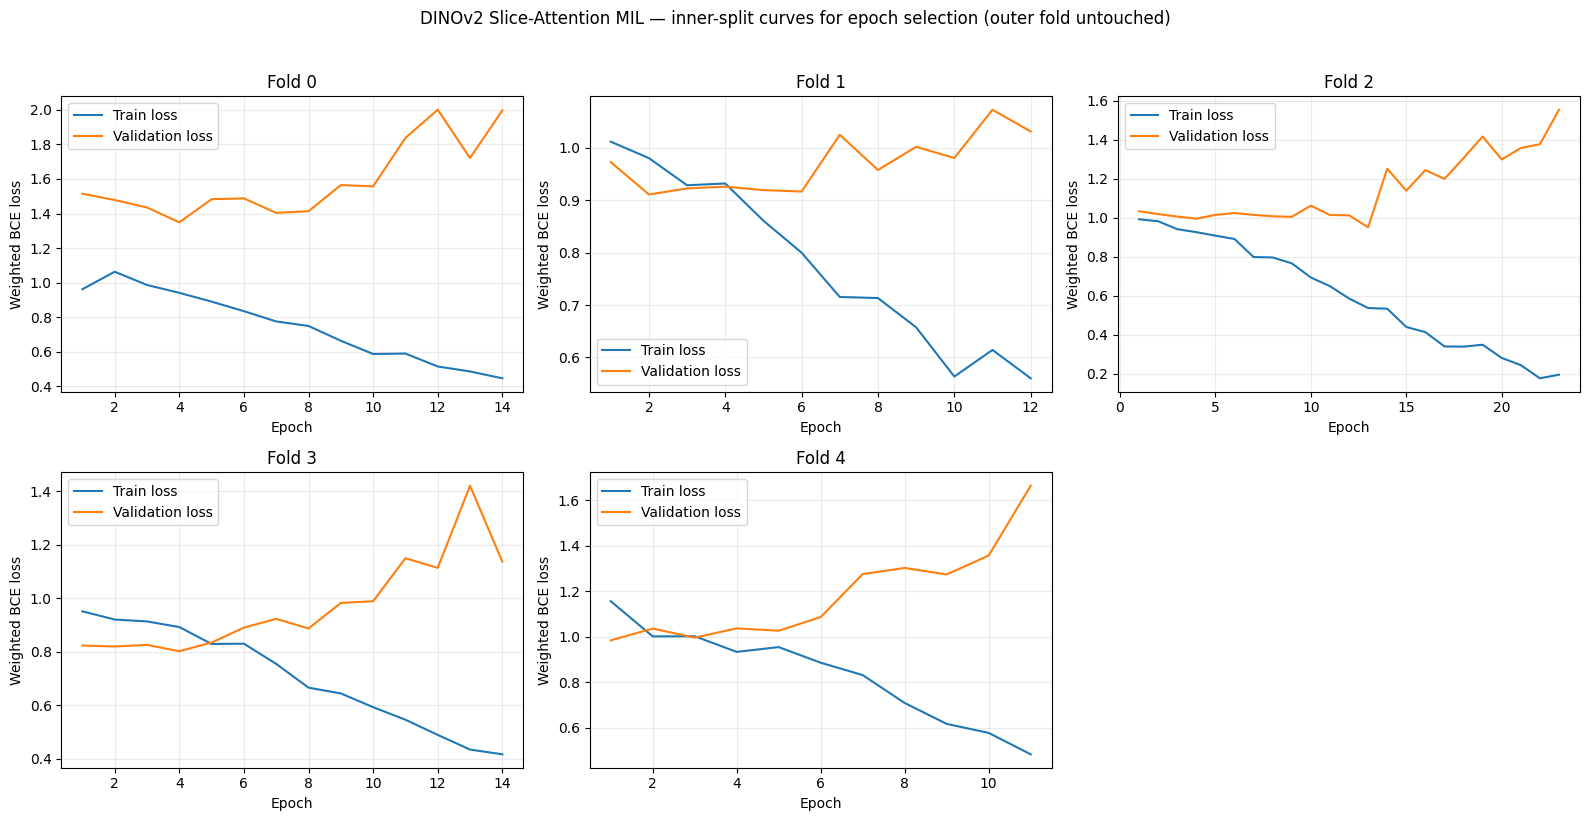

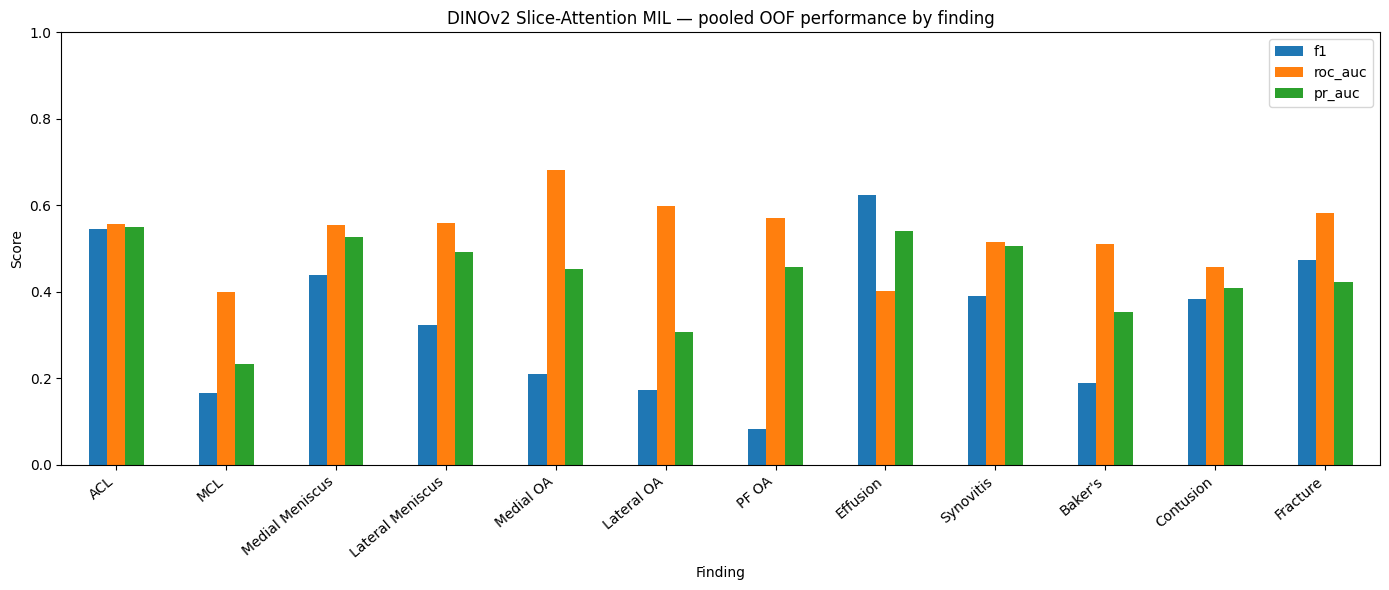

Saved: /kaggle/working/dinov2_slice_attention_learning_curves.png
Saved: /kaggle/working/dinov2_slice_attention_oof_per_class_metrics.png


In [12]:
# Training and validation loss curves, one panel per fold.
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=False, sharey=False)
axes = axes.flatten()
for fold in range(N_FOLDS):
    ax = axes[fold]
    fold_hist = all_history_df[all_history_df["fold"] == fold]
    ax.plot(fold_hist["epoch"], fold_hist["train_loss"], label="Train loss")
    ax.plot(fold_hist["epoch"], fold_hist["val_loss"], label="Validation loss")
    ax.set_title(f"Fold {fold}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Weighted BCE loss")
    ax.grid(alpha=0.25)
    ax.legend()
axes[-1].axis("off")
fig.suptitle("DINOv2 Slice-Attention MIL — inner-split curves for epoch selection (outer fold untouched)", y=1.02)
fig.tight_layout()
learning_curve_path = os.path.join(OUTPUT_DIR, f"{BASE}_learning_curves.png")
fig.savefig(learning_curve_path, dpi=160, bbox_inches="tight")
plt.show()

# Pooled OOF per-finding performance. ROC/PR AUC are NaN when a class has no positives or no negatives in OOF.
plot_metrics = per_class_df.set_index("label")[["f1", "roc_auc", "pr_auc"]]
ax = plot_metrics.plot(kind="bar", figsize=(14, 6))
ax.set_title("DINOv2 Slice-Attention MIL — pooled OOF performance by finding")
ax.set_xlabel("Finding")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
per_class_plot_path = os.path.join(OUTPUT_DIR, f"{BASE}_oof_per_class_metrics.png")
plt.savefig(per_class_plot_path, dpi=160, bbox_inches="tight")
plt.show()

print("Saved:", learning_curve_path)
print("Saved:", per_class_plot_path)

## 13. Inspect the highest-attention instances in one held-out study

Example held-out study: 1.2.826.0.1.3680043.8.498.13267780356245120052411517053322874891


,StudyInstanceUID,SeriesInstanceUID,Center_Slice_Index,Anatomical_Plane,attention_weight
2698,1.2.826.0.1.3680043.8.498.13267780356245120052...,1.2.826.0.1.3680043.8.498.63041321193340816564...,21,Coronal,0.993457
2699,1.2.826.0.1.3680043.8.498.13267780356245120052...,1.2.826.0.1.3680043.8.498.63041321193340816564...,19,Coronal,0.005313
2700,1.2.826.0.1.3680043.8.498.13267780356245120052...,1.2.826.0.1.3680043.8.498.63041321193340816564...,20,Coronal,0.000684
2701,1.2.826.0.1.3680043.8.498.13267780356245120052...,1.2.826.0.1.3680043.8.498.63041321193340816564...,22,Coronal,0.000232
2702,1.2.826.0.1.3680043.8.498.13267780356245120052...,1.2.826.0.1.3680043.8.498.18633001863723640513...,17,Sagittal,0.000083
2703,1.2.826.0.1.3680043.8.498.13267780356245120052...,1.2.826.0.1.3680043.8.498.63041321193340816564...,18,Coronal,0.000055
2704,1.2.826.0.1.3680043.8.498.13267780356245120052...,1.2.826.0.1.3680043.8.498.18633001863723640513...,1,Sagittal,0.000045
2705,1.2.826.0.1.3680043.8.498.13267780356245120052...,1.2.826.0.1.3680043.8.498.11601405247092213838...,17,Sagittal,0.000040
2706,1.2.826.0.1.3680043.8.498.13267780356245120052...,1.2.826.0.1.3680043.8.498.11601405247092213838...,2,Sagittal,0.000025
2707,1.2.826.0.1.3680043.8.498.13267780356245120052...,1.2.826.0.1.3680043.8.498.11601405247092213838...,1,Sagittal,0.000022


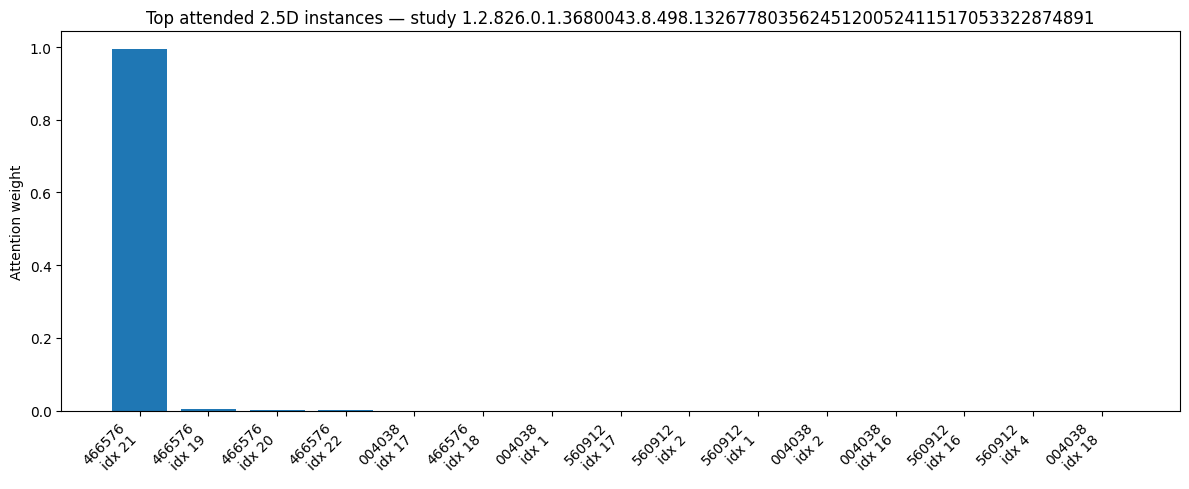

Saved: /kaggle/working/dinov2_slice_attention_top_attention_example.png


In [13]:
# This is a diagnostic view of the learned weights, not a pixel-level saliency map or a clinical explanation.
example_study = (
    attention_weights_df.groupby("StudyInstanceUID")["attention_weight"].max().sort_values(ascending=False).index[0]
)
example_attention = (
    attention_weights_df[attention_weights_df["StudyInstanceUID"] == example_study]
    .sort_values("attention_weight", ascending=False)
    .head(15)
    .copy()
)

print("Example held-out study:", example_study)
cols_show = [c for c in [
    "StudyInstanceUID", "SeriesInstanceUID", "Center_Slice_Index", "Anatomical_Plane", "attention_weight"
] if c in example_attention.columns]
display(example_attention[cols_show])

labels_for_plot = []
for _, row in example_attention.iterrows():
    series_short = str(row.get("SeriesInstanceUID", "series"))[-6:]
    center = row.get("Center_Slice_Index", "?")
    labels_for_plot.append(f"{series_short}\nidx {center}")

plt.figure(figsize=(12, 5))
plt.bar(range(len(example_attention)), example_attention["attention_weight"].to_numpy())
plt.xticks(range(len(example_attention)), labels_for_plot, rotation=45, ha="right")
plt.ylabel("Attention weight")
plt.title(f"Top attended 2.5D instances — study {example_study}")
plt.tight_layout()
example_attention_plot_path = os.path.join(OUTPUT_DIR, f"{BASE}_top_attention_example.png")
plt.savefig(example_attention_plot_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", example_attention_plot_path)

## 14. Optional comparison against Notebooks 07 and 08

In [14]:
# Optional comparison: load EfficientNet/ViT rows only from attached Kaggle inputs.
# Always load this notebook's own row from its known /kaggle/working path so it
# cannot be mistaken for proof that all three models were compared.

def find_input_artifacts(filename):
    matches = []
    base = "/kaggle/input"
    if not os.path.exists(base):
        return matches
    for current, dirs, files in os.walk(base):
        dirs[:] = [d for d in dirs if d not in PRUNE_DIRS]
        if filename in files:
            matches.append(os.path.join(current, filename))
    return sorted(set(matches))

comparison_frames = []
missing_comparison_models = []

previous_model_artifacts = [
    ("EfficientNet-B0", "efficientnet_b0_comparison_row.csv"),
    ("ViT-S/16", "vit_s16_comparison_row.csv"),
]

for model_name, filename in previous_model_artifacts:
    paths = find_input_artifacts(filename)
    if not paths:
        missing_comparison_models.append(model_name)
        print(
            f"NOT FOUND: {filename}. Attach the saved output dataset from the corresponding notebook "
            "if you want this model included in the combined table."
        )
        continue
    if len(paths) > 1:
        missing_comparison_models.append(model_name)
        print(f"AMBIGUOUS: multiple copies of {filename} were found:")
        for path in paths:
            print("  -", path)
        print("Attach only the intended/latest output copy and rerun this cell.")
        continue

    path = paths[0]
    try:
        frame = pd.read_csv(path)
        if frame.empty or "model" not in frame.columns:
            raise ValueError("Comparison CSV must be non-empty and contain a 'model' column.")
        comparison_frames.append(frame)
        print(f"Loaded {model_name} comparison artifact: {path}")
    except Exception as exc:
        missing_comparison_models.append(model_name)
        print(f"Could not read {model_name} artifact {path}: {exc}")

# This path is created in Section 9 by Notebook 10 itself; do not discover it by
# recursively searching /kaggle/working, which can obscure missing 07/08 rows.
if os.path.exists(comparison_path):
    own_row = pd.read_csv(comparison_path)
    if not own_row.empty and "model" in own_row.columns:
        comparison_frames.append(own_row)
        print("Loaded current Notebook 10 comparison row:", comparison_path)
    else:
        print("Notebook 10 comparison row is missing the expected model field:", comparison_path)
else:
    print("Notebook 10 comparison row not found. Run Section 9 first:", comparison_path)

if comparison_frames:
    comparison_table = pd.concat(comparison_frames, ignore_index=True, sort=False)
    if "model" in comparison_table.columns:
        comparison_table = comparison_table.drop_duplicates(subset=["model"], keep="last")
    display(comparison_table)
else:
    print("No valid comparison-row artifacts were available.")

if missing_comparison_models:
    print(
        "\nCOMPARISON INCOMPLETE — missing or ambiguous prior model row(s): "
        + ", ".join(missing_comparison_models)
    )
    print(
        "The table must not be reported as a three-model comparison until these rows are attached "
        "and loaded. Notebook 10 training/evaluation does not depend on these optional inputs."
    )
else:
    print("All three model rows are present. Confirm their metric definitions and aggregation methods match before reporting.")

Loaded EfficientNet-B0 comparison artifact: /kaggle/input/notebooks/minnieg12/07-efficientnet/efficientnet_b0_comparison_row.csv
Loaded ViT-S/16 comparison artifact: /kaggle/input/notebooks/minnieg12/08-vit/vit_s16_comparison_row.csv
Loaded current Notebook 10 comparison row: /kaggle/working/dinov2_slice_attention_comparison_row.csv


,model,input,aggregation,loss,threshold,folds_completed,macro_auc_mean,macro_auc_std,macro_pr_auc_mean,macro_pr_auc_std,...,macro_pr_auc,macro_precision,macro_recall,macro_f1,macro_specificity,micro_f1,hamming_loss,subset_accuracy,n_gold_studies,n_folds
0,EfficientNet-B0,2.5D previous/current/next slices,mean instance-logit pooling,weighted BCE,0.5,5.0,0.535003,0.059622,0.523504,0.067369,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ViT-S/16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.506968,0.287907,0.296925,0.257234,0.748228,0.401413,0.365278,0.0,NaN,NaN
2,DINOv2 ViT-S/14 + flat slice-attention MIL,NaN,NaN,NaN,0.5,NaN,NaN,NaN,NaN,NaN,...,0.529735,0.317302,0.372480,0.278984,0.685667,0.401245,0.400253,0.0,58.0,5.0


All three model rows are present. Confirm their metric definitions and aggregation methods match before reporting.


## 15. Final artifact checklist and interpretation notes

In [15]:
expected_outputs = [
    f"{BASE}_fold_results.csv",
    f"{BASE}_oof_predictions.csv",
    f"{BASE}_metric_summary.csv",
    f"{BASE}_comparison_row.csv",
    f"{BASE}_all_history.csv",
    f"{BASE}_oof_per_class_metrics.csv",
    f"{BASE}_oof_error_analysis.csv",
    f"{BASE}_oof_attention_weights.csv",
    f"{BASE}_oof_series_attention_mass.csv",
    f"{BASE}_learning_curves.png",
    f"{BASE}_oof_per_class_metrics.png",
    f"{BASE}_top_attention_example.png",
]
expected_outputs.extend([f"{BASE}_fold_{fold}.pth" for fold in range(N_FOLDS)])

print("Notebook 10 output checklist:")
for name in expected_outputs:
    path = os.path.join(OUTPUT_DIR, name)
    print(("OK   " if os.path.exists(path) else "MISS ") + name)

print("\nFinal study-level OOF metric summary:")
display(metric_summary_df)

print("\nImportant interpretation notes:")
print("1. Outer held-out folds are evaluated only after epoch selection on an inner split and refitting on all outer-training studies.")
print("2. Splits are study-level: slices from one StudyInstanceUID never cross fold boundaries.")
print("3. Threshold is fixed at 0.50, matching the preliminary baseline evaluation convention.")
print("4. AUC/PR-AUC for rare findings may be undefined in an individual fold if that fold has only one class.")
print("5. Attention weights rank 2.5D instances within a study; they are not pixel-level saliency maps.")
print("6. This is a flat slice-attention baseline. Series-level attention and the full hierarchy belong to later notebooks.")

Notebook 10 output checklist:
OK   dinov2_slice_attention_fold_results.csv
OK   dinov2_slice_attention_oof_predictions.csv
OK   dinov2_slice_attention_metric_summary.csv
OK   dinov2_slice_attention_comparison_row.csv
OK   dinov2_slice_attention_all_history.csv
OK   dinov2_slice_attention_oof_per_class_metrics.csv
OK   dinov2_slice_attention_oof_error_analysis.csv
OK   dinov2_slice_attention_oof_attention_weights.csv
OK   dinov2_slice_attention_oof_series_attention_mass.csv
OK   dinov2_slice_attention_learning_curves.png
OK   dinov2_slice_attention_oof_per_class_metrics.png
OK   dinov2_slice_attention_top_attention_example.png
OK   dinov2_slice_attention_fold_0.pth
OK   dinov2_slice_attention_fold_1.pth
OK   dinov2_slice_attention_fold_2.pth
OK   dinov2_slice_attention_fold_3.pth
OK   dinov2_slice_attention_fold_4.pth

Final study-level OOF metric summary:


,metric,mean,std
0,macro_auc,0.523941,0.050742
1,macro_pr_auc,0.529735,0.067732
2,macro_precision,0.317302,0.142847
3,macro_recall,0.372480,0.103973
4,macro_f1,0.278984,0.109814
5,macro_specificity,0.685667,0.061374
6,micro_f1,0.401245,0.096357
7,hamming_loss,0.400253,0.034377
8,subset_accuracy,0.000000,0.000000



Important interpretation notes:
1. Outer held-out folds are evaluated only after epoch selection on an inner split and refitting on all outer-training studies.
2. Splits are study-level: slices from one StudyInstanceUID never cross fold boundaries.
3. Threshold is fixed at 0.50, matching the preliminary baseline evaluation convention.
4. AUC/PR-AUC for rare findings may be undefined in an individual fold if that fold has only one class.
5. Attention weights rank 2.5D instances within a study; they are not pixel-level saliency maps.
6. This is a flat slice-attention baseline. Series-level attention and the full hierarchy belong to later notebooks.
